# 04 · E4: tuning YOLOv8s

YOLOv8s is the model to deploy (real time; see notebook 08), so it is the one we tune. Each trial is a shorter run
(up to 25 epochs, early stopping after 10) and is judged **only on validation**. The test set is not touched here.

**Round 1: one change at a time** against a reference, so each effect can be attributed:

| Trial | Change | Why it might help |
|---|---|---|
| E4a_ref | none (640 px, batch 32) | reference |
| E4b_img960 | input 960 px instead of 640 | KITTI images are 1242 px wide; at 640 px distant pedestrians and cyclists shrink to a few pixels |
| E4c_rfs | repeat-factor sampling | cyclists, trams and seated persons are rare; RFS shows them more often |

Every change that improves the validation primary metric by at least 0.005 is kept.

**Round 2: on top of the round-1 choice.** The combination itself, and the same with a **5× lower learning rate**
(0.002), because earlier runs reached their best validation score within the first few epochs and then got worse:
the usual sign that fine-tuning moves too far from the pretrained weights. The best round-2 trial on validation
gives the final settings, which notebook 05 trains in full.

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## Data

In [2]:
tables = prepare_data()

copy images/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy labels/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: train 4699, val 1239, test 1543


## Class imbalance and the RFS repeat factors

How often each class appears in the training images, and how many times RFS repeats an image that contains it.

RFS: 4699 training images -> 6157 per epoch


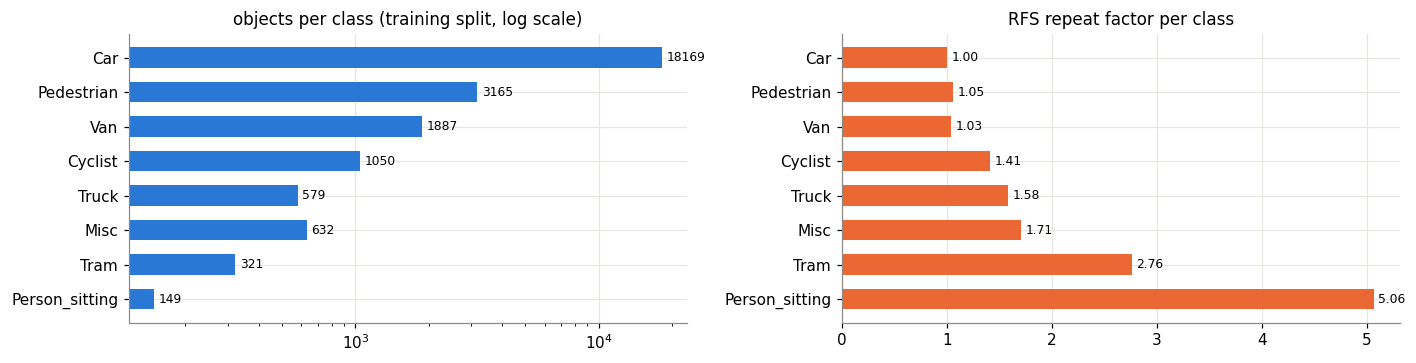

,img_fraction,class_repeat
type,,
Car,0.882,1.000
Pedestrian,0.270,1.055
Van,0.280,1.035
Cyclist,0.150,1.412
Truck,0.120,1.582
Misc,0.103,1.708
Tram,0.039,2.760
Person_sitting,0.012,5.063


In [3]:
images, ann, ign = tables
tr = split_ids(images, "train")
counts = ann[ann.image_id.isin(set(tr))]["type"].value_counts().reindex(CLASSES)
rfs_yaml, rfs_table, n_per_epoch = write_rfs_list(tables)
rfs_table.to_csv(exp_dir("E4") / "rfs_class_repeat.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
bars = ax[0].barh(CLASSES[::-1], counts.values[::-1], color=TRAIN_C, height=0.6)
ax[0].bar_label(bars, fontsize=8, padding=3); ax[0].set_xscale("log"); ax[0].set_title("objects per class (training split, log scale)")
bars = ax[1].barh(CLASSES[::-1], rfs_table.class_repeat.values[::-1], color=VAL_C, height=0.6)
ax[1].bar_label(bars, fmt="%.2f", fontsize=8, padding=3); ax[1].set_title("RFS repeat factor per class")
plt.tight_layout(); fig.savefig(exp_dir("E4") / "figures" / "class_balance.png", dpi=130); plt.show()
rfs_table.round(3)

## Round 1

In [4]:
TUNE_EPOCHS = 25
ROUND1 = {"E4a_ref":    dict(imgsz=640, batch=32),
          "E4b_img960": dict(imgsz=960, batch=16),
          "E4c_rfs":    dict(imgsz=640, batch=32, rfs=True)}
trials = {}


def run_trial(tid, cfg, note):
    cfg = dict(cfg)
    rfs, imgsz, batch = cfg.pop("rfs", False), cfg.pop("imgsz"), cfg.pop("batch")
    data = rfs_yaml if rfs else DATA / "kitti.yaml"
    w, info = yolo_train(tid, "yolov8s.pt", data, imgsz=imgsz, epochs=TUNE_EPOCHS, batch=batch, **cfg)
    val, _, _ = evaluate_model(tid, "yolo", w, tables, "val", imgsz=imgsz)
    info["settings"] = json.dumps({"imgsz": imgsz, "batch": batch, "rfs": rfs, **cfg})
    save_record(tid, f"tuning: {note}", "tuning", val=val, **info)
    trials[tid] = {"val": val, "info": info}
    print(f"{tid}: validation primary {val['primary_mAP50_mod']:.3f} (best epoch {info['best_epoch']})")


for tid, cfg in ROUND1.items():
    run_trial(tid, cfg, tid.split("_", 1)[1])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
training E4a_ref: yolov8s.pt, up to 25 epochs, imgsz 640, batch 32, changes: none
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/kitti.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=N

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/25      6.49G      1.199     0.8719      1.007        322        640: 100% ━━━━━━━━━━━━ 147/147 2.8it/s 52.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 4.1it/s 4.9s
                   all       1239       7296      0.628      0.442       0.47       0.28

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/25      6.79G      1.197     0.8556      1.004        352        640: 100% ━━━━━━━━━━━━ 147/147 2.8it/s 51.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 4.1it/s 4.9s
                   all       1239       7296      0.459      0.419      0.412      0.234

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/25      6.79G      1.196     0.8387      1.013        309        640: 100% ━━━━━━━━━━━━ 147/147 2.8it/s 51.9s
                 Class     Images  Instances      Box

E4a_ref on val:   0%|          | 0/78 [00:00<?, ?it/s]

E4a_ref: validation primary 0.670 (best epoch 2)
training E4b_img960: yolov8s.pt, up to 25 epochs, imgsz 960, batch 16, changes: none
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/kitti.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None

E4b_img960 on val:   0%|          | 0/78 [00:00<?, ?it/s]

E4b_img960: validation primary 0.787 (best epoch 2)
training E4c_rfs: yolov8s.pt, up to 25 epochs, imgsz 640, batch 32, changes: none
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/train_rfs.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=

E4c_rfs on val:   0%|          | 0/78 [00:00<?, ?it/s]

E4c_rfs: validation primary 0.682 (best epoch 2)


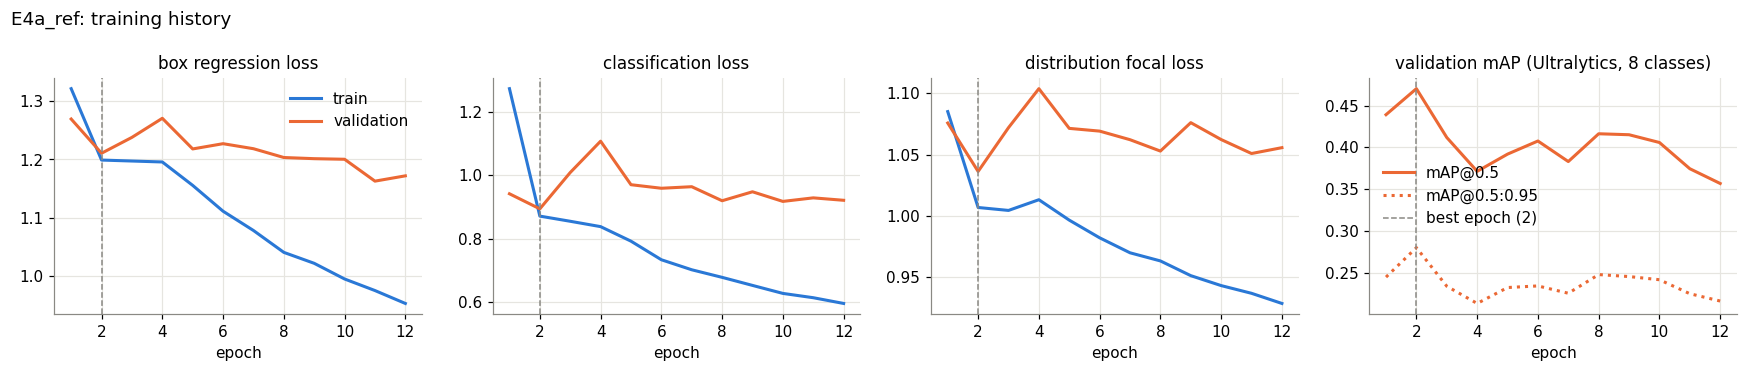

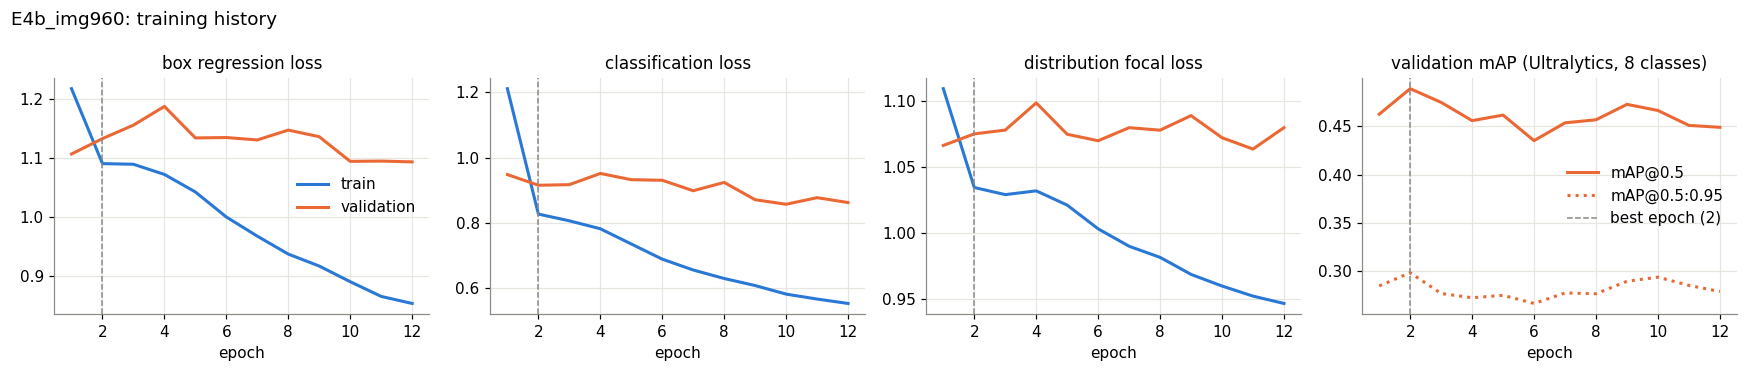

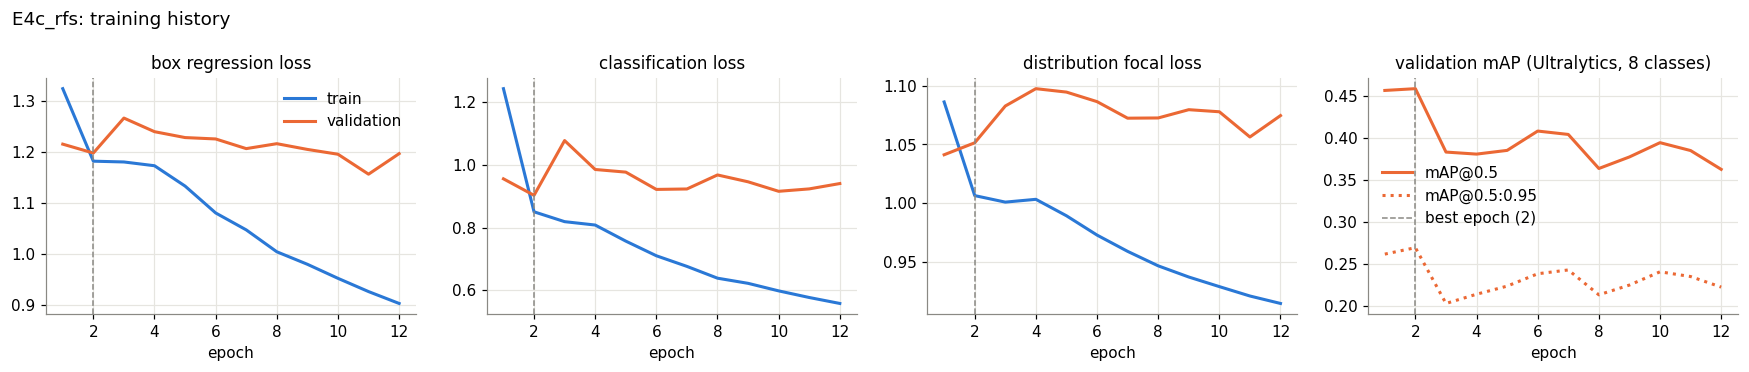

In [5]:
for tid in ROUND1:
    plot_yolo_history(tid)

**Round-1 choice.** Keep each change that beat the reference by at least 0.005 on validation.

In [6]:
ref = trials["E4a_ref"]["val"]["primary_mAP50_mod"]
chosen, kept = dict(ROUND1["E4a_ref"]), []
for tid in ["E4b_img960", "E4c_rfs"]:
    gain = trials[tid]["val"]["primary_mAP50_mod"] - ref
    print(f"{tid}: {gain:+.3f} vs reference")
    if gain >= 0.005:
        chosen.update({k: v for k, v in ROUND1[tid].items() if ROUND1["E4a_ref"].get(k) != v})
        kept.append(tid)
print("round-1 settings:", chosen, "| kept:", kept or "none")

E4b_img960: +0.117 vs reference
E4c_rfs: +0.012 vs reference
round-1 settings: {'imgsz': 960, 'batch': 16, 'rfs': True} | kept: ['E4b_img960', 'E4c_rfs']


## Round 2

`E4d_combined` is the round-1 settings together (only trained if more than one change was kept; otherwise it is the
same as an existing trial) and `E4e_lr002` the same with learning rate 0.002.

training E4d_combined: yolov8s.pt, up to 25 epochs, imgsz 960, batch 16, changes: none
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/train_rfs.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=

E4d_combined on val:   0%|          | 0/78 [00:00<?, ?it/s]

E4d_combined: validation primary 0.732 (best epoch 18)
training E4e_lr002: yolov8s.pt, up to 25 epochs, imgsz 960, batch 16, changes: {'lr0': 0.002}
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/train_rfs.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, 

E4e_lr002 on val:   0%|          | 0/78 [00:00<?, ?it/s]

E4e_lr002: validation primary 0.779 (best epoch 3)


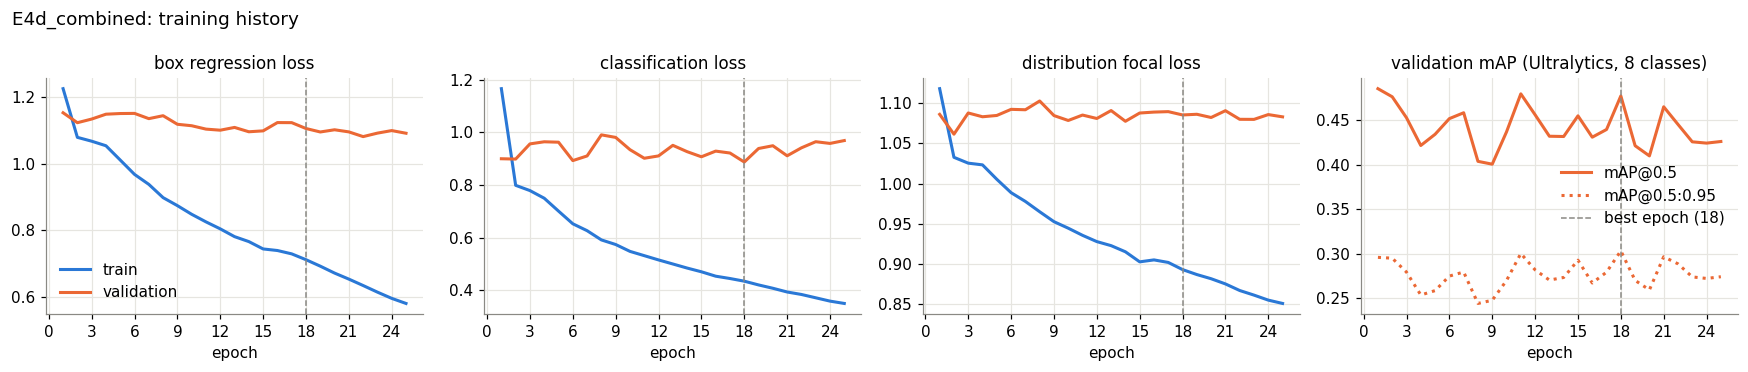

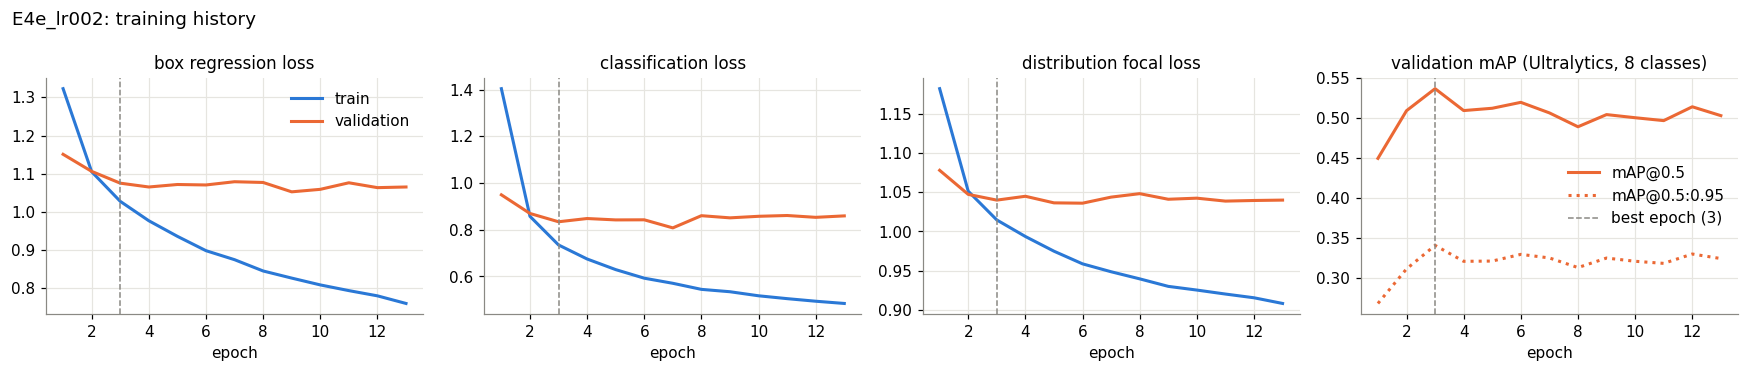

In [7]:
same_as = kept[0] if len(kept) == 1 else ("E4a_ref" if not kept else None)
if same_as is None:
    run_trial("E4d_combined", chosen, "round-1 changes combined")
    base_trial = "E4d_combined"
else:
    base_trial = same_as
    print(f"round-1 settings equal {same_as}; no extra run needed")
run_trial("E4e_lr002", {**chosen, "lr0": 0.002}, "round-1 settings + lr 0.002")
for tid in [t for t in ["E4d_combined", "E4e_lr002"] if t in trials]:
    plot_yolo_history(tid)

## All trials and the final choice

In [8]:
summary = pd.DataFrame([{"trial": t, "settings": r["info"]["settings"], "best_epoch": r["info"]["best_epoch"],
                         "epochs_run": r["info"]["epochs_run"], "train_hours": r["info"]["train_hours"],
                         "val_primary": r["val"]["primary_mAP50_mod"], "val_Car": r["val"]["AP50_Car_moderate"],
                         "val_Pedestrian": r["val"]["AP50_Pedestrian_moderate"],
                         "val_Cyclist": r["val"]["AP50_Cyclist_moderate"], "val_mAP50_all8": r["val"]["mAP50_all8"]}
                        for t, r in trials.items()])
summary.to_csv(exp_dir("E4") / "tuning_summary.csv", index=False)

final_trial = max([base_trial, "E4e_lr002"], key=lambda t: trials[t]["val"]["primary_mAP50_mod"])
final_cfg = {**chosen, "lr0": 0.002} if final_trial == "E4e_lr002" else chosen
choice = {"base": "yolov8s.pt", "config": final_cfg, "chosen_trial": final_trial, "round1_kept": kept,
          "val_primary": {t: r["val"]["primary_mAP50_mod"] for t, r in trials.items()}}
(RESULTS / "final_config.json").write_text(json.dumps(choice, indent=1))
print("FINAL settings:", final_cfg, "(from", final_trial + ")")
summary.round(3)

FINAL settings: {'imgsz': 960, 'batch': 16, 'rfs': True, 'lr0': 0.002} (from E4e_lr002)


,trial,settings,best_epoch,epochs_run,train_hours,val_primary,val_Car,val_Pedestrian,val_Cyclist,val_mAP50_all8
0,E4a_ref,"{""imgsz"": 640, ""batch"": 32, ""rfs"": false}",2,12,0.218,0.670,0.958,0.700,0.351,0.464
1,E4b_img960,"{""imgsz"": 960, ""batch"": 16, ""rfs"": false}",2,12,0.432,0.787,0.974,0.769,0.617,0.475
2,E4c_rfs,"{""imgsz"": 640, ""batch"": 32, ""rfs"": true}",2,12,0.269,0.682,0.962,0.677,0.407,0.407
3,E4d_combined,"{""imgsz"": 960, ""batch"": 16, ""rfs"": true}",18,25,1.133,0.732,0.968,0.683,0.545,0.448
4,E4e_lr002,"{""imgsz"": 960, ""batch"": 16, ""rfs"": true, ""lr0""...",3,13,0.601,0.779,0.968,0.770,0.599,0.514


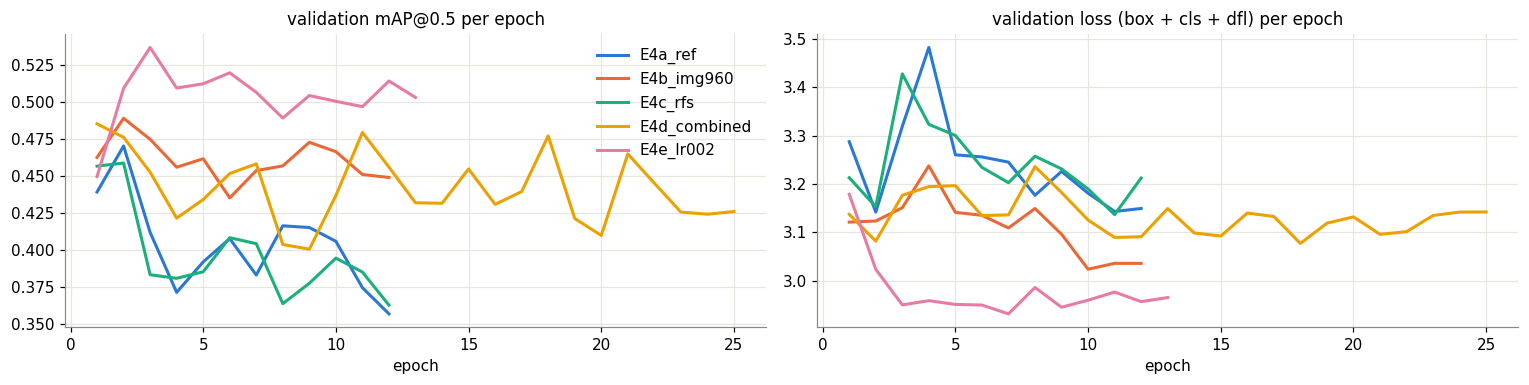

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for i, t in enumerate(trials):
    h = pd.read_csv(exp_dir(t) / "history.csv")
    ax[0].plot(h.epoch, h["metrics/mAP50(B)"], color=PALETTE[i], label=t)
    ax[1].plot(h.epoch, h["val/box_loss"] + h["val/cls_loss"] + h["val/dfl_loss"], color=PALETTE[i], label=t)
ax[0].set_title("validation mAP@0.5 per epoch"); ax[1].set_title("validation loss (box + cls + dfl) per epoch")
for a in ax:
    a.set_xlabel("epoch")
ax[0].legend()
plt.tight_layout(); fig.savefig(exp_dir("E4") / "figures" / "trials_overlay.png", dpi=130); plt.show()

## Observations

| trial | settings | val primary | Cyclist | best epoch / run |
|---|---|---|---|---|
| E4a_ref | 640 px, batch 32 | 0.670 | 0.351 | 2 / 12 |
| E4b_img960 | 960 px, batch 16 | **0.787** | **0.617** | 2 / 12 |
| E4c_rfs | 640 px + repeat-factor sampling | 0.682 | 0.407 | 2 / 12 |
| E4d_combined | 960 px + RFS | 0.732 | 0.545 | 18 / 25 |
| E4e_lr002 | 960 px + RFS + lr 0.002 | 0.779 | 0.599 | 3 / 13 |

- **Image size is by far the most useful change: +0.117**, almost all of it from cyclists (0.351 → 0.617), which are
  small objects that lose too many pixels at 640 px.
- **Repeat-factor sampling helps a little on its own (+0.012)**, again through cyclists (0.351 → 0.407).
- **Combining the two at the default learning rate was worse than 960 px alone (0.732).** RFS repeats rare images,
  so each epoch has about 30 % more steps; with learning rate 0.01 the run trained much longer (best epoch 18) and
  ended worse. Lowering the learning rate to 0.002 recovered most of the loss (0.779).
- **A note on the choice.** The rule set before the runs compared only the round-2 trials (E4d, E4e), so it picked
  E4e (0.779), although 960 px alone (E4b) scored 0.008 higher. That gap is smaller than run-to-run noise: notebook 05
  retrains exactly E4e's settings and gets 0.758 on validation, 0.021 below E4e. The final settings are therefore kept
  as chosen, and the gap is reported here rather than hidden.